Mounted at /content/drive
First 5 rows:
   Id  SepalLengthCm  SepalWidthCm  PetalLengthCm  PetalWidthCm      Species
0   1            5.1           3.5            1.4           0.2  Iris-setosa
1   2            4.9           3.0            1.4           0.2  Iris-setosa
2   3            4.7           3.2            1.3           0.2  Iris-setosa
3   4            4.6           3.1            1.5           0.2  Iris-setosa
4   5            5.0           3.6            1.4           0.2  Iris-setosa

Dataset Shape:
(150, 6)

Columns:
Index(['Id', 'SepalLengthCm', 'SepalWidthCm', 'PetalLengthCm', 'PetalWidthCm',
       'Species'],
      dtype='object')


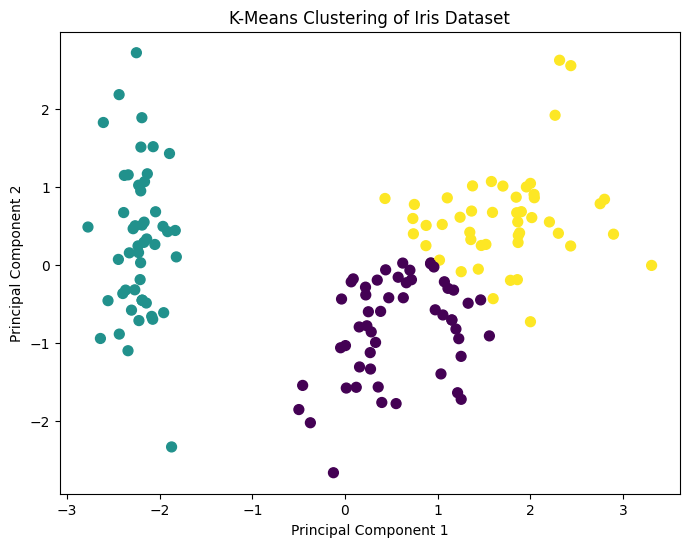

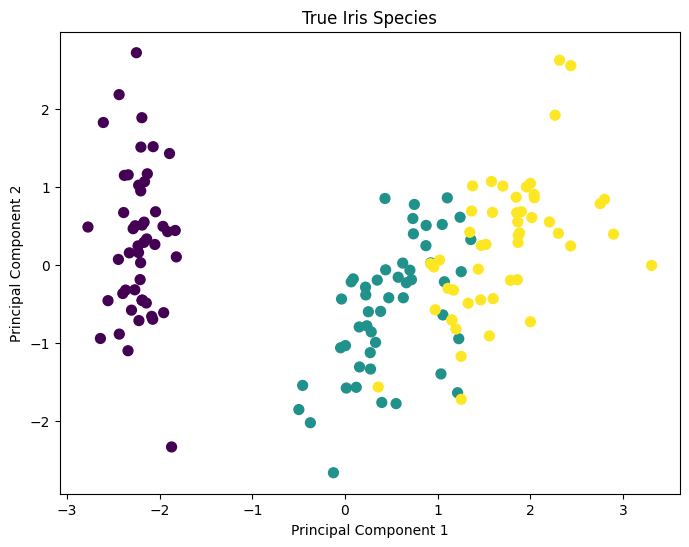

Adjusted Rand Index: 0.6201351808870379

Final Dataset:
   Id  SepalLengthCm  SepalWidthCm  PetalLengthCm  PetalWidthCm      Species  \
0   1            5.1           3.5            1.4           0.2  Iris-setosa   
1   2            4.9           3.0            1.4           0.2  Iris-setosa   
2   3            4.7           3.2            1.3           0.2  Iris-setosa   
3   4            4.6           3.1            1.5           0.2  Iris-setosa   
4   5            5.0           3.6            1.4           0.2  Iris-setosa   
5   6            5.4           3.9            1.7           0.4  Iris-setosa   
6   7            4.6           3.4            1.4           0.3  Iris-setosa   
7   8            5.0           3.4            1.5           0.2  Iris-setosa   
8   9            4.4           2.9            1.4           0.2  Iris-setosa   
9  10            4.9           3.1            1.5           0.1  Iris-setosa   

   Cluster  
0        1  
1        1  
2        1  
3        1 

In [2]:
# 1. Import libraries
import pandas as pd
import matplotlib.pyplot as plt

from google.colab import drive
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import adjusted_rand_score

# 2. Mount Google Drive
drive.mount('/content/drive')

# 3. Load Iris CSV database
df = pd.read_csv('/content/drive/MyDrive/ML Practical/Iris.csv')

# 4. Display dataset
print("First 5 rows:")
print(df.head())

print("\nDataset Shape:")
print(df.shape)

print("\nColumns:")
print(df.columns)

# 5. Select features
X = df[['SepalLengthCm',
        'SepalWidthCm',
        'PetalLengthCm',
        'PetalWidthCm']]

# 6. True labels
y = df['Species']

# 7. Standardize features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# 8. Apply K-Means
kmeans = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

df['Cluster'] = kmeans.fit_predict(X_scaled)

# 9. Apply PCA
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

# 10. Visualize clusters
plt.figure(figsize=(8, 6))

plt.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=df['Cluster'],
    cmap='viridis',
    s=50
)

plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.title('K-Means Clustering of Iris Dataset')

plt.show()

# 11. Encode true species labels
encoder = LabelEncoder()
true_labels = encoder.fit_transform(y)

# 12. Visualize true labels
plt.figure(figsize=(8, 6))

plt.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=true_labels,
    cmap='viridis',
    s=50
)

plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.title('True Iris Species')

plt.show()

# 13. Compare clusters with true labels
ari = adjusted_rand_score(true_labels, df['Cluster'])

print("Adjusted Rand Index:", ari)

# 14. Display final data
print("\nFinal Dataset:")
print(df.head(10))